In [1]:
import pandas as pd
from pathlib import Path

file_path = Path("Sample - Superstore.csv")

df = pd.read_csv(file_path, encoding="latin1")
print("Dataset loaded successfully!")
print("Row and columns: ", df.shape)

display(df.head())

Dataset loaded successfully!
Row and columns:  (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
# check all column names
print("COLUMN NAMES: ")
print(df.columns.tolist())

# check data types and non-null counts
print("\nDataset Information: ")
df.info()

# check missing values
print("\nMISSING VALUES: ")
print(df.isnull().sum())

# check chech duplicate rows
print("\nDUPLICATE ROWS: ", df.duplicated().sum())

# statistical summary
print("\nNUMERICAL SUMMARY: ")
display(df.describe())

COLUMN NAMES: 
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Dataset Information: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    999

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [3]:
df_clean = df.copy()

# Convert date columns into datetime format
df_clean["Order Date"] = pd.to_datetime(df_clean["Order Date"], errors="coerce")

df_clean["Ship Date"] = pd.to_datetime(df_clean["Ship Date"], errors="coerce")

# treat Postal Code as an identifier , not a measurement
df_clean["Postal Code"] = df_clean["Postal Code"].astype("string")

# Verify the changes
print("Updated data types: ")
print(df_clean[["Order Date", "Ship Date", "Postal Code"]].dtypes)

print("\nInvalid dates: ")
print(df_clean[["Order Date", "Ship Date"]].isna().sum())

Updated data types: 
Order Date     datetime64[ns]
Ship Date      datetime64[ns]
Postal Code    string[python]
dtype: object

Invalid dates: 
Order Date    0
Ship Date     0
dtype: int64


## Business rules validate

In [4]:
# check for invalid sales, quantity, discount and profit

print("Sales <= 0: ", (df_clean["Sales"] <= 0).sum())
print("Quantity <= 0: ", (df_clean["Quantity"] <= 0).sum())

print("Discount outside 0-1: ", (~df_clean["Discount"].between(0,1)).sum())

print("Order date after ship date: ", (df_clean["Order Date"] > df_clean["Ship Date"]).sum())

print("\nNegative profit records: ", (df_clean[ "Profit"] < 0).sum())

print("\nUnique orders: ", df_clean["Order ID"].nunique())
print("\nunique customers: ", df_clean["Customer ID"].nunique())
print("\nUnique products: ", df_clean["Product ID"].nunique())

Sales <= 0:  0
Quantity <= 0:  0
Discount outside 0-1:  0
Order date after ship date:  0

Negative profit records:  1871

Unique orders:  5009

unique customers:  793

Unique products:  1862


## Business Analysis: Sales and Profit by Category

In [5]:
category_analysis = (df_clean.groupby("Category").agg(Total_Sales=("Sales", "sum"),
                                                     Total_Profit=("Profit", "sum"),
                                                     Total_Quantity=("Quantity","sum"),
                                                     Order_Lines=("Order ID", "size")
                                                     ).sort_values("Total_Sales", ascending=False))
category_analysis["Profit_Margine_%"] = (category_analysis["Total_Profit"] / category_analysis["Total_Sales"] *100)

display(category_analysis.round(2))

,Total_Sales,Total_Profit,Total_Quantity,Order_Lines,Profit_Margine_%
Category,,,,,
Technology,836154.03,145454.95,6939,1847,17.40
Furniture,741999.80,18451.27,8028,2121,2.49
Office Supplies,719047.03,122490.80,22906,6026,17.04


## Visualization
Category wise Sales VS Profit bar chart

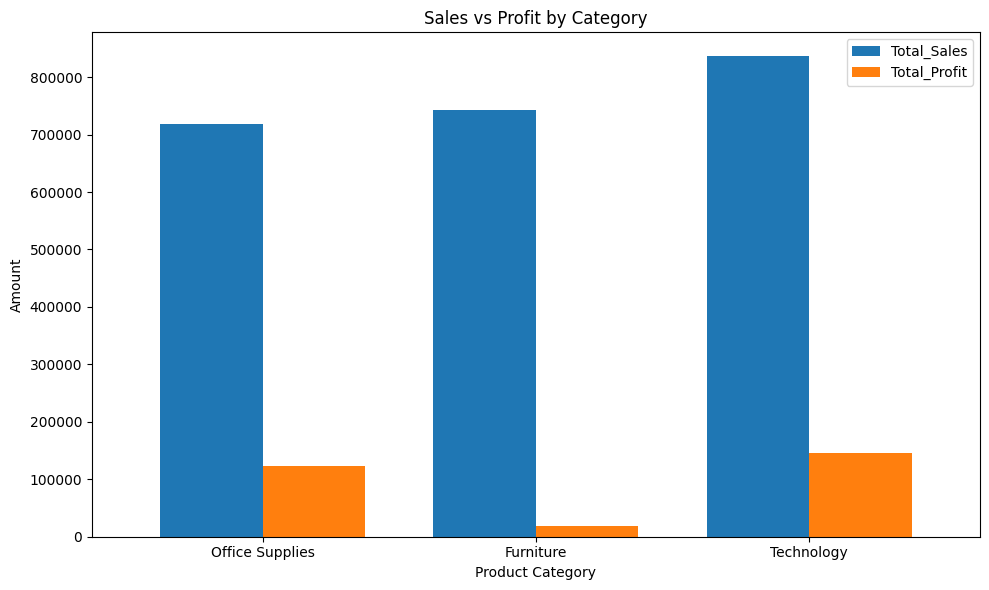

In [6]:
import matplotlib.pyplot as plt

plot_data = category_analysis[["Total_Sales", "Total_Profit"]].sort_values("Total_Sales")

ax = plot_data.plot(kind="bar", figsize=(10,6), width=0.75)

ax.set_title("Sales vs Profit by Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Amount")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

In [7]:
import numpy as np
import pandas as pd
print("Numpy version: ", np.__version__)
print("Pandas version: ", pd.__version__)
try:
    import matplotlib
    print("Matplotlib version: ", matplotlib.__version__)
except Exception as e:
    print("Matplotlib error: ", repr(e))

Numpy version:  1.26.4
Pandas version:  2.3.1
Matplotlib version:  3.6.3


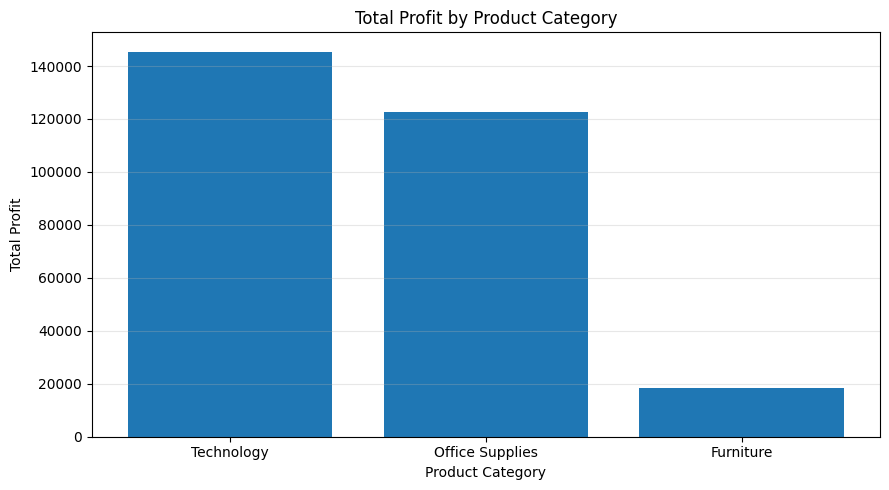

In [8]:
profit_data = category_analysis.sort_values("Total_Profit", ascending=False)

plt.figure(figsize=(9,5))
plt.bar(profit_data.index, profit_data["Total_Profit"])

plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Sub-category profit analysis

In [9]:
subcategory_analysis = (df_clean.groupby(["Category", "Sub-Category"]).agg(
                                                                        Total_Sales=("Sales", "sum"),
                                                                        Total_Profit=("Profit", "sum"),
                                                                        Total_Quantity=("Quantity", "sum")).reset_index())

furniture_analysis = (subcategory_analysis[subcategory_analysis["Category"] == "Furniture"].sort_values("Total_Profit"))

display(furniture_analysis.round(2))

,Category,Sub-Category,Total_Sales,Total_Profit,Total_Quantity
3,Furniture,Tables,206965.53,-17725.48,1241
0,Furniture,Bookcases,114880.00,-3472.56,868
2,Furniture,Furnishings,91705.16,13059.14,3563
1,Furniture,Chairs,328449.10,26590.17,2356


# Furniture - discount vs profit

In [10]:
furniture_discount_analysis = (df_clean[df_clean["Category"] == "Furniture"]
                              .groupby(["Sub-Category", "Discount"])
                              .agg(Total_Sales=("Sales", "sum"),
                                  Total_Profit=("Profit", "sum"),
                                  Order_Lines=("Order ID", "size")
                                ).reset_index()
                                  .sort_values(["Sub-Category", "Discount"]))

display(furniture_discount_analysis.round(2))

,Sub-Category,Discount,Total_Sales,Total_Profit,Order_Lines
0,Bookcases,0.00,31935.98,6075.71,60
1,Bookcases,0.15,27558.52,1418.99,52
2,Bookcases,0.20,26841.50,130.50,46
3,Bookcases,0.30,4282.70,-555.87,10
4,Bookcases,0.32,14493.46,-2391.14,27
5,Bookcases,0.50,7308.46,-4255.81,18
6,Bookcases,0.70,2459.38,-3894.94,15
7,Chairs,0.00,91060.73,21933.10,133
8,Chairs,0.10,46634.25,7111.01,76
9,Chairs,0.20,120748.62,4283.18,250


## Discount and profit visual comparison

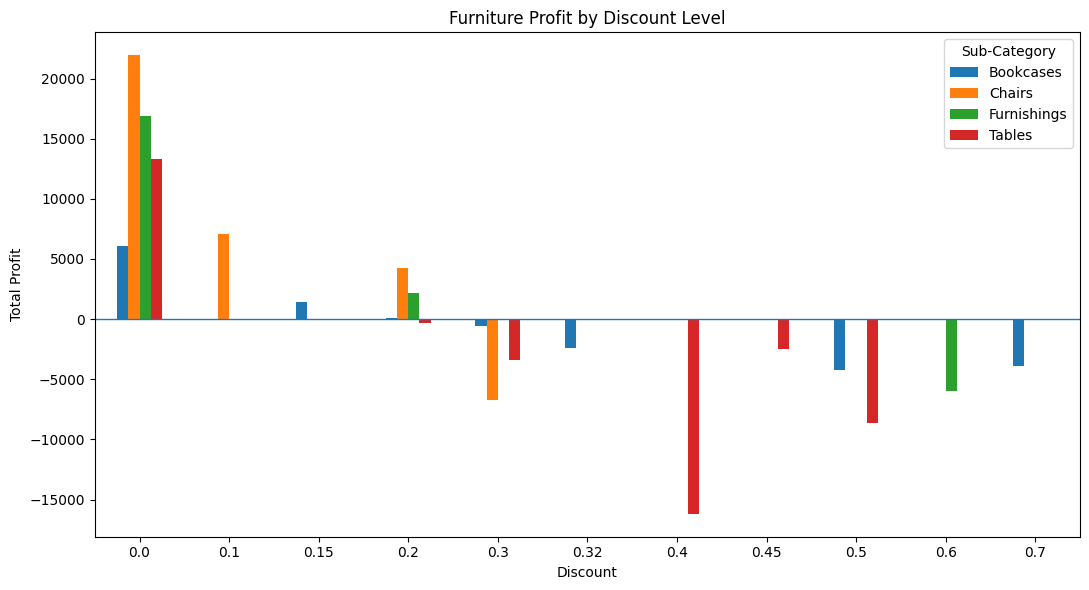

In [11]:
import matplotlib.pyplot as plt

furniture_discount_pivot = (furniture_discount_analysis.pivot(index="Discount",
                                                              columns="Sub-Category",
                                                              values="Total_Profit"))

furniture_discount_pivot.plot(kind="bar", figsize=(11,6))

plt.title("Furniture Profit by Discount Level")
plt.xlabel("Discount")
plt.ylabel("Total Profit")
plt.axhline(0, linewidth=1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Top loss making Tables products

In [12]:
tables_product_analysis = (df_clean[(df_clean["Category"] == "Furniture") & (df_clean["Sub-Category"] == "Tables")]
                          .groupby("Product Name")
                          .agg(
                              Total_Sales=("Sales", "sum"),
                              Total_Profit=("Profit", "sum"),
                              Total_Quantity=("Quantity", "sum"),
                              Avg_Discount=("Discount", "mean")
                          ).reset_index()
                            .sort_values("Total_Profit")
)

display(tables_product_analysis.head(10).round(2))

,Product Name,Total_Sales,Total_Profit,Total_Quantity,Avg_Discount
28,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.64,-2876.12,27,0.28
22,Bush Advantage Collection Racetrack Conference...,9544.72,-1934.40,33,0.35
3,Balt Solid Wood Round Tables,6518.75,-1201.06,19,0.20
17,BoxOffice By Design Rectangular and Half-Moon ...,1706.25,-1148.44,15,0.48
51,"Riverside Furniture Oval Coffee Table, Oval En...",4446.18,-1147.40,25,0.30
21,Bretford Just In Time Height-Adjustable Mult...,5634.90,-964.19,17,0.22
10,"Bevis Oval Conference Table, Walnut",6942.07,-856.01,36,0.28
1,BPI Conference Tables,2241.87,-795.97,26,0.37
39,Hon 94000 Series Round Tables,7404.50,-681.21,30,0.16
27,"Chromcraft Bull-Nose Wood 48"" x 96"" Rectangula...",4297.64,-611.59,11,0.33


C:\Users\PRANAV\AppData\Local\Temp\ipykernel_9500\1510842524.py:10: UserWarning: Glyph 147 (\x93) missing from current font.
  plt.tight_layout()
C:\Users\PRANAV\AppData\Local\Temp\ipykernel_9500\1510842524.py:10: UserWarning: Glyph 148 (\x94) missing from current font.
  plt.tight_layout()
C:\Users\PRANAV\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 147 (\x93) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\PRANAV\AppData\Local\Programs\Python\Python310\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 148 (\x94) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


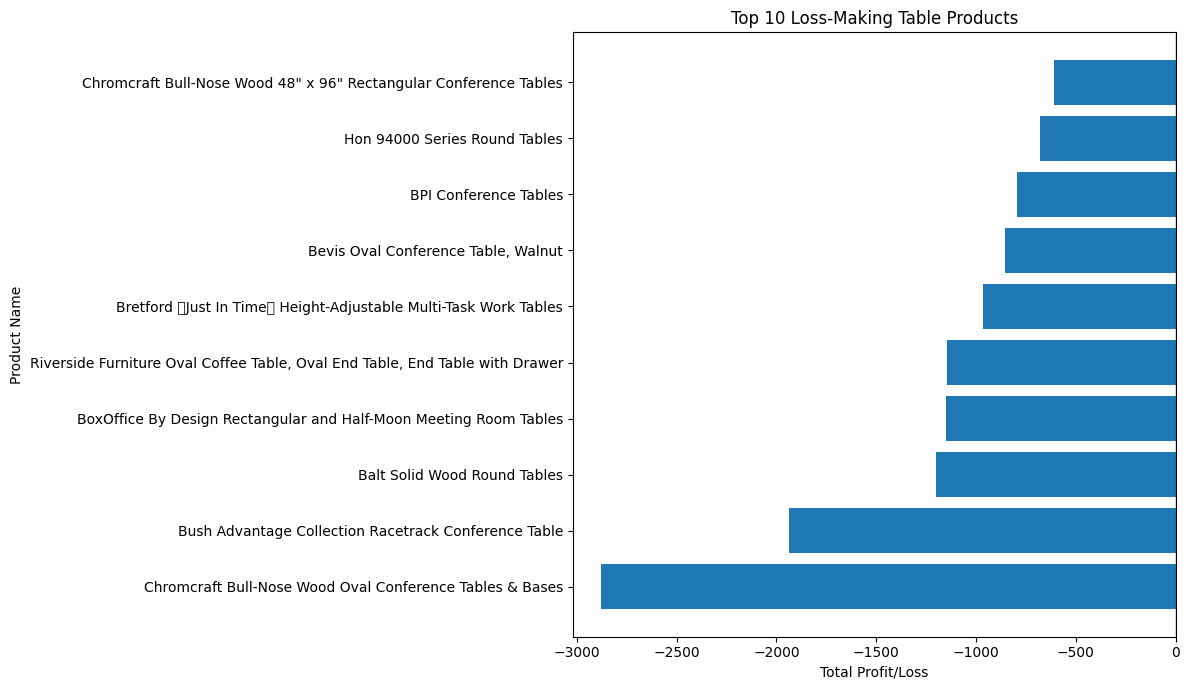

In [13]:
loss_data = tables_product_analysis.head(10).sort_values("Total_Profit")

plt.figure(figsize=(12,7))
plt.barh(loss_data["Product Name"], loss_data["Total_Profit"])

plt.title("Top 10 Loss-Making Table Products")
plt.xlabel("Total Profit/Loss")
plt.ylabel("Product Name")
plt.axvline(0, linewidth=1)
plt.tight_layout()
plt.show()

# Summary of loss making products 

In [14]:
top_10_loss_products = tables_product_analysis.sort_values("Total_Profit", ascending=True).head(10).copy()

# top_10_loss_products["Loss_Magnitude"] = (-top_10_loss_products["Total_Profit"])

display_df = top_10_loss_products.copy()

display_df["Total_Sales"] = display_df["Total_Sales"].map(lambda x: f"${x:,.2f}")
display_df["Total_Profit"] = display_df["Total_Profit"].map(lambda x: f"-${abs(x):,.2f}" if x<0 else f"${x:,.2f}")
display_df["Total_Quantity"] = display_df["Total_Quantity"].map(lambda x: f"{x:,.0f}")
display_df["Avg_Discount"] = display_df["Avg_Discount"].map(lambda x: f"{x:.1%}")
display(display_df)

,Product Name,Total_Sales,Total_Profit,Total_Quantity,Avg_Discount
28,Chromcraft Bull-Nose Wood Oval Conference Tabl...,"$9,917.64","-$2,876.12",27,28.0%
22,Bush Advantage Collection Racetrack Conference...,"$9,544.73","-$1,934.40",33,35.0%
3,Balt Solid Wood Round Tables,"$6,518.75","-$1,201.06",19,20.0%
17,BoxOffice By Design Rectangular and Half-Moon ...,"$1,706.25","-$1,148.44",15,48.3%
51,"Riverside Furniture Oval Coffee Table, Oval En...","$4,446.18","-$1,147.40",25,30.0%
21,Bretford Just In Time Height-Adjustable Mult...,"$5,634.90",-$964.19,17,22.5%
10,"Bevis Oval Conference Table, Walnut","$6,942.07",-$856.01,36,27.5%
1,BPI Conference Tables,"$2,241.87",-$795.97,26,37.0%
39,Hon 94000 Series Round Tables,"$7,404.50",-$681.21,30,16.0%
27,"Chromcraft Bull-Nose Wood 48"" x 96"" Rectangula...","$4,297.64",-$611.59,11,33.3%


### Business Insights — Loss-Making Table Products

- Chromcraft Bull-Nose Wood Oval Conference Tables recorded the highest loss among the top 10 products, at approximately $2,876.12
- Bush Advantage Collection Racetrack Conference Table recorded the second highest loss, at approximately -$1,934.40.
- Several table products generated sales but still resulted in negative profit.
- The company should review product pricing, discount policies, and costs for these loss-making products.
- Further analysis is required to determine whether discounts, product costs, or other factors are contributing to the losses.



The analysis identified several table products generating negative profits despite recording sales. The company should review discount policies, evaluate product pricing and associated costs, and monitor product-level profitability regularly. Discount experiments should be conducted to identify profitable discount ranges while considering product mix and order volume. These actions can help reduce losses and support better pricing decisions.

**Note:** The observed relationship between discounts and losses does not establish causation. Further analysis is required before implementing major pricing changes.

# Monthly Sales & Profit Trend

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

monthly_analysis = (df_clean.set_index("Order Date").resample("MS")
                  .agg(
                      Total_Sales=("Sales", "sum"),
                      Total_Profit=("Profit", "sum"),
                      Order_Lines=("Order ID", "size")).reset_index())

display(monthly_analysis.round(2))

,Order Date,Total_Sales,Total_Profit,Order_Lines
0,2014-01-01,14236.90,2450.19,79
1,2014-02-01,4519.89,862.31,46
2,2014-03-01,55691.01,498.73,157
3,2014-04-01,28295.34,3488.84,135
4,2014-05-01,23648.29,2738.71,122
5,2014-06-01,34595.13,4976.52,135
6,2014-07-01,33946.39,-841.48,143
7,2014-08-01,27909.47,5318.10,153
8,2014-09-01,81777.35,8328.10,268
9,2014-10-01,31453.39,3448.26,159


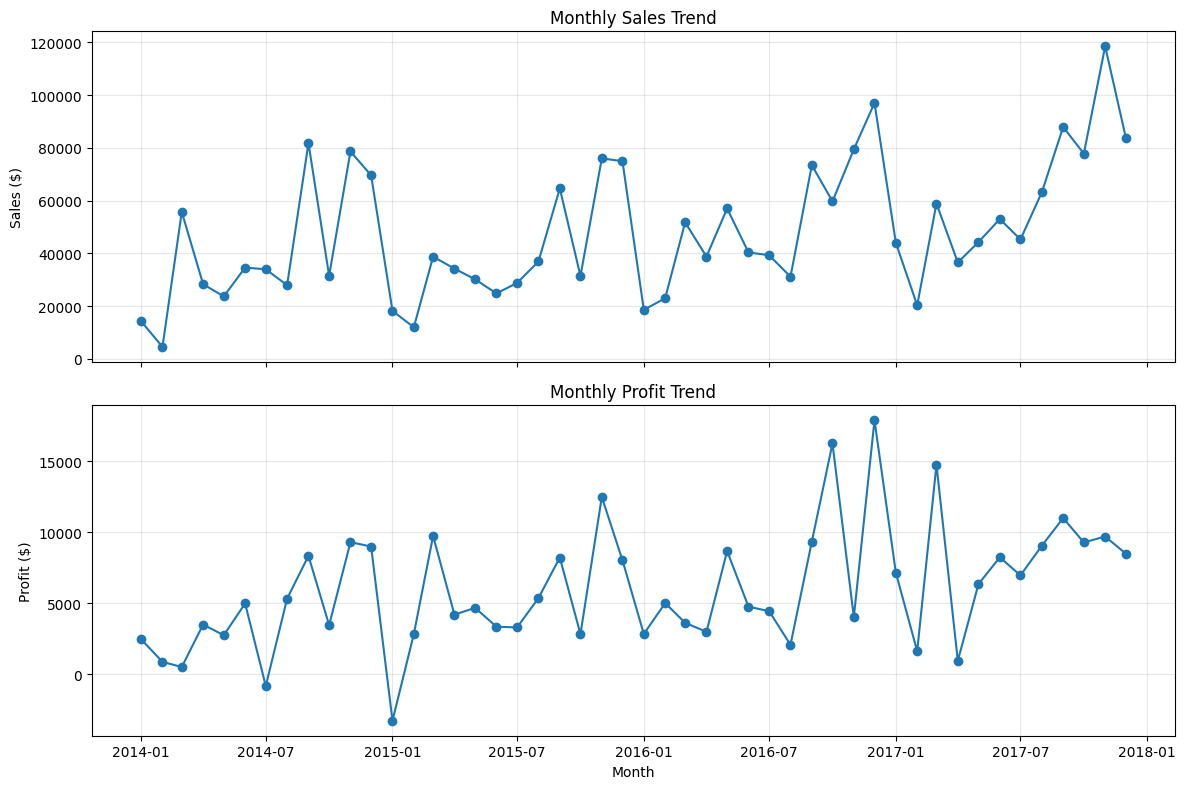

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(12,8), sharex=True)

axes[0].plot(monthly_analysis["Order Date"], monthly_analysis["Total_Sales"], marker="o")
axes[0].set_title("Monthly Sales Trend")
axes[0].set_ylabel("Sales ($)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(monthly_analysis["Order Date"], monthly_analysis["Total_Profit"], marker="o")
axes[1].set_title("Monthly Profit Trend")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Profit ($)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Monthly Sales and Profit Analysis - Key Insights
1. Monthly sales show noticeable fluctuations throughout the 2014 - 2017 period
2. November 2017 recorded the highest monthly sales, at approximately 108,000
3. Monthly profit also fluctuated, with a few months recording negative profits
4. December 2016 recorded a significant profit peak of approximately 17,500
5. The business should monitor monthly profitability alongside sales to identify periods of weak financial performance.

### Business Recommendation:
Analyze seasonal sales patterns, investigate months with negative profits, and monitor pricing and operating costs to improve profitability

# Region-wise Sales & Profit Analysis

In [17]:
region_analysis = (df_clean.groupby("Region")
                  .agg(
                      Total_Sales=("Sales", "sum"),
                      Total_Profit=("Profit", "sum"),
                      Total_Quantity=("Quantity", "sum"),
                      Order_Lines=("Order ID", "size")
                  ).sort_values("Total_Sales", ascending=False)
)

region_analysis["Profit_Margin_%"] = (region_analysis["Total_Profit"] / region_analysis["Total_Sales"] * 100)

display(region_analysis.round(2))

,Total_Sales,Total_Profit,Total_Quantity,Order_Lines,Profit_Margin_%
Region,,,,,
West,725457.82,108418.45,12266,3203,14.94
East,678781.24,91522.78,10618,2848,13.48
Central,501239.89,39706.36,8780,2323,7.92
South,391721.90,46749.43,6209,1620,11.93


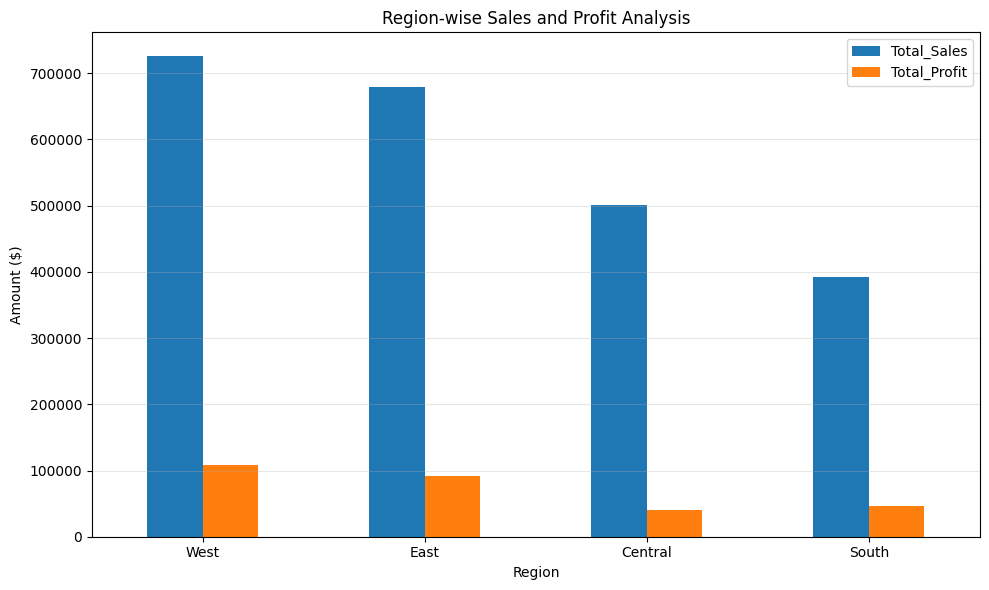

In [18]:
region_analysis[["Total_Sales", "Total_Profit"]].plot(kind="bar", figsize=(10, 6))

plt.title("Region-wise Sales and Profit Analysis")
plt.xlabel("Region")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Region-wise Sales and Profit Analysis - Key Insights

1. The West region generated the highest sales (725,457.82) and profit (108,418.45)
2. The East region ranked second in both sales and profit
3. The Central region recorded the lowest profit margin at 7.92% , indicating an opportinity to improve profitability
4. The South region generated lower sales than Central but achieved higher total profit.

### Business Recommendation: 
The company should maintain the strong performance of the West and East regions while investigating the Cesntral region's pricing, discount structure, product mix, and operating costs

# Segment-wise Analysis

In [19]:
segment_analysis =(df_clean.groupby("Segment")
                  .agg(
                      Total_Sales=("Sales", "sum"),
                      Total_Profit=("Profit", "sum"),
                      Total_Quantity=("Quantity", "sum"),
                      Order_Lines=("Order ID", "size")
                  ).sort_values("Total_Sales", ascending=False)
)

segment_analysis["Profit_Margin_%"] = (segment_analysis["Total_Profit"] / segment_analysis["Total_Sales"] * 100)

display(segment_analysis.round(2))

,Total_Sales,Total_Profit,Total_Quantity,Order_Lines,Profit_Margin_%
Segment,,,,,
Consumer,1161401.34,134119.21,19521,5191,11.55
Corporate,706146.37,91979.13,11608,3020,13.03
Home Office,429653.15,60298.68,6744,1783,14.03


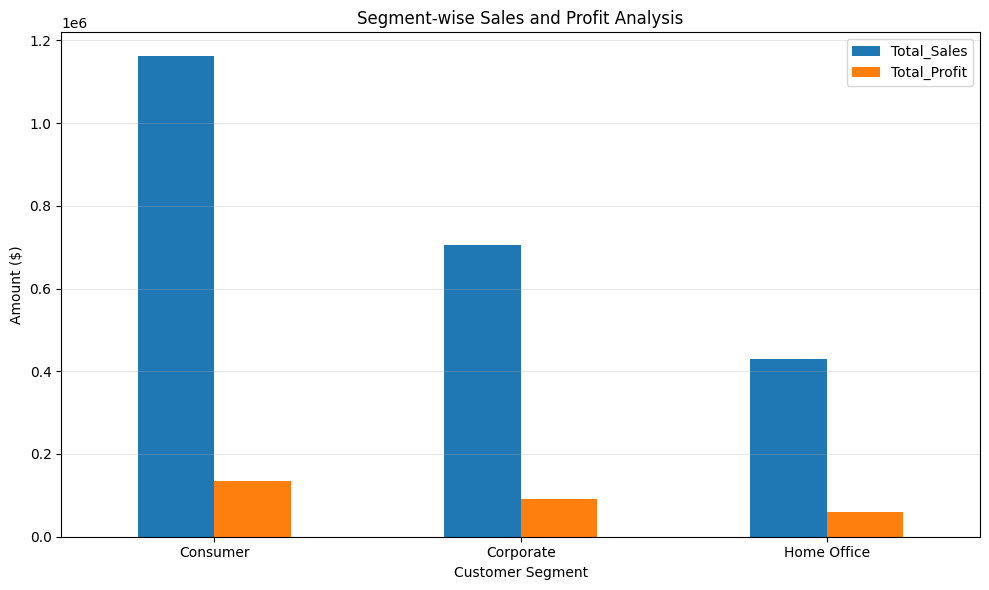

In [20]:
segment_analysis[["Total_Sales", "Total_Profit"]].plot(kind="bar", figsize=(10,6))
plt.title("Segment-wise Sales and Profit Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Segment-wise Sales and Profit Analysis - Key Insights
 1. The Consumer segment generated the highest sales (1,161,401.34) and total profit (134,119.21)
 2. The Corporate segment contributed 706,146.37 in sales and 91,979.13 in profit
 3. The Home Office segment achieved the highest profit margin of 14.03% , despit having the lowest sales.
 4. Consumer customers represent the largest revenue opportunity, while Home Office customers demonstrate comparatively stronger profitability per dollar of sales.
 
### Business Recommendation: 
Maintain the consumer segment's strong sales performance while exploring opportinities to grow the Home Office segment. The company should also focus on improving the Consumer segment's profit margin

## Shipping Analysis

In [21]:
shipping_analysis = (df_clean.groupby("Ship Mode")
                    .agg(
                        Total_Sales=("Sales", "sum"),
                        Total_Profit=("Profit", "sum"),
                        Total_Quantity=("Quantity", "sum"),
                        Order_Lines=("Order ID", "size")
                    ).sort_values("Total_Sales", ascending=False)
)

shipping_analysis["Profit_Margin_%"] = (shipping_analysis["Total_Profit"] / shipping_analysis["Total_Sales"] * 100)

display(shipping_analysis.round(2))

,Total_Sales,Total_Profit,Total_Quantity,Order_Lines,Profit_Margin_%
Ship Mode,,,,,
Standard Class,1358215.74,164088.79,22797,5968,12.08
Second Class,459193.57,57446.64,7423,1945,12.51
First Class,351428.42,48969.84,5693,1538,13.93
Same Day,128363.12,15891.76,1960,543,12.38


### Shipping Mode Analysis - Key Insights

1. Standard Class generated the highest sales (1,358,215.74) and total profit (164,088.79)
2. First Class achieved the highest profit margin of 13.93%
3. Second Class recorded a profit margin of 12.51%
4. Same Day shipping contributed the lowest sales and total profit

### Business Recommendation:

Continue monitoring Standard Class as the major sales contributor and evaluate the profitability and customer demand of First Class shipping. 
Review Same Day shipping costs and pricing to identify opportunities for improvement.

## Shipping Analysis Chart

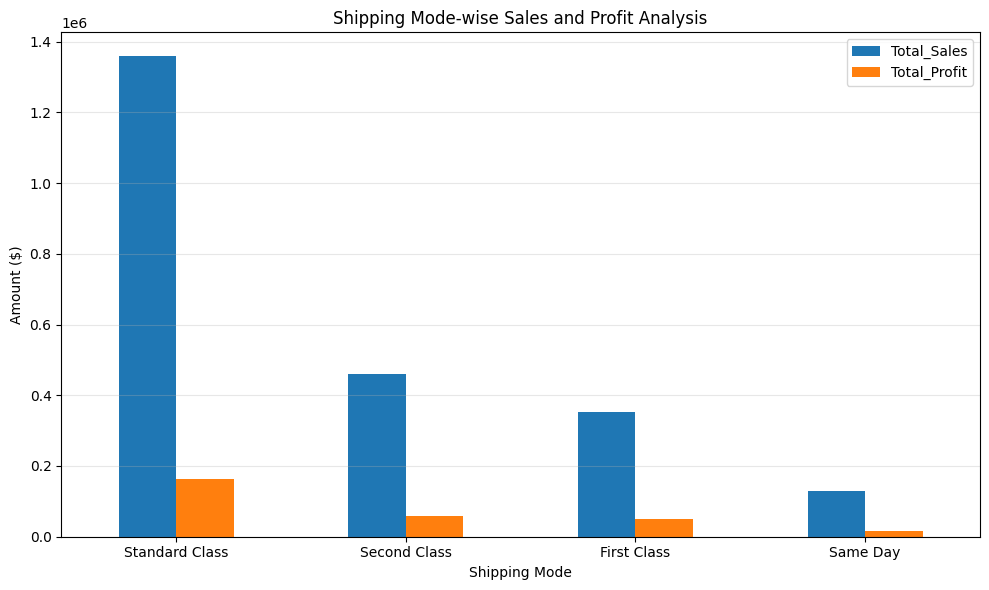

In [23]:
shipping_analysis[["Total_Sales", "Total_Profit"]].plot(kind="bar", figsize=(10,6))

plt.title("Shipping Mode-wise Sales and Profit Analysis")
plt.xlabel("Shipping Mode")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Top 10 & Bottom 10 Products Analysis

### 1. Top 10 Profitable Products

In [31]:
product_analysis = (df_clean.groupby("Product Name")
                   .agg(
                       Total_Sales=("Sales", "sum"),
                       Total_Profit=("Profit", "sum"),
                       Total_Quantity=("Quantity", "sum")
                   ).reset_index()
)

top_10_products = (product_analysis.sort_values("Total_Profit", ascending=False).head(10))

display(top_10_products.round(2))

,Product Name,Total_Sales,Total_Profit,Total_Quantity
404,Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93,20
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38,7753.04,31
805,Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88,38
400,Canon PC1060 Personal Laser Copier,11619.83,4570.93,19
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.90,4094.98,12
165,Ativa V4110MDD Micro-Cut Shredder,7699.89,3772.95,11
19,"3D Systems Cube Printer, 2nd Generation, Magenta",14299.89,3717.97,11
1276,Plantronics Savi W720 Multi-Device Wireless He...,9367.29,3696.28,24
895,Ibico EPK-21 Electric Binding System,15875.92,3345.28,13
1840,Zebra ZM400 Thermal Label Printer,6965.70,3343.54,6


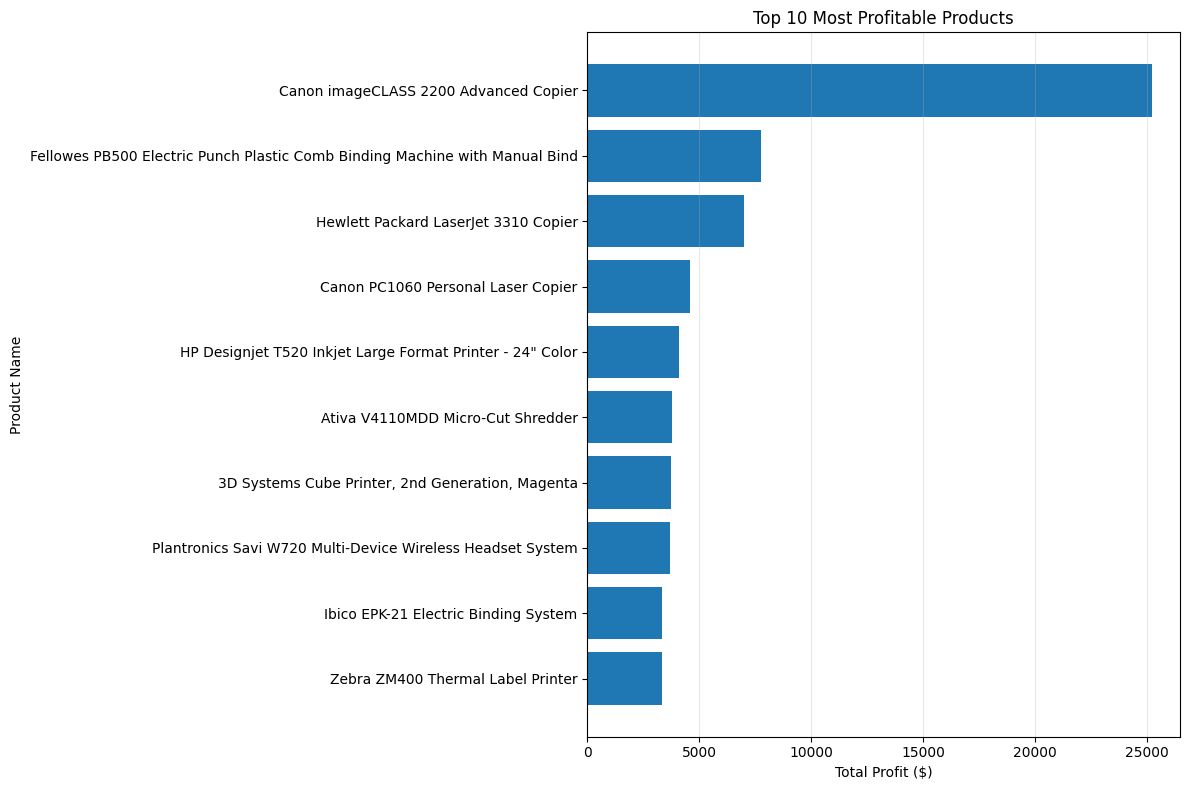

In [34]:
top_10_chart = top_10_products.sort_values("Total_Profit", ascending=True)

plt.figure(figsize=(12,8))

plt.barh(top_10_chart["Product Name"], top_10_chart["Total_Profit"])

plt.title("Top 10 Most Profitable Products")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product Name")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Business Insights

1. Canon imageCLASS 2200 Copier is the strongest profit-generating product.
2. Fellowes PB500 Electric Punch is second, with 7,753.04 profit.
3. Technology products dominate the top profitable products list.
4. High-value products can generate substantial profit even with relatively low sales quantities.

### 2. Bottom 10 Loss - Making Products

In [38]:
bottom_10_products = (product_analysis.sort_values("Total_Profit", ascending=True).head(10))

display(bottom_10_products.round(2))

,Product Name,Total_Sales,Total_Profit,Total_Quantity
475,Cubify CubeX 3D Printer Double Head Print,11099.96,-8879.97,9
985,Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97,18
476,Cubify CubeX 3D Printer Triple Head Print,7999.98,-3839.99,4
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.64,-2876.12,27
376,Bush Advantage Collection Racetrack Conference...,9544.72,-1934.40,33
683,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17,27
444,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08,6
1043,Martin Yale Chadless Opener Electric Letter Op...,16656.20,-1299.18,22
285,Balt Solid Wood Round Tables,6518.75,-1201.06,19
364,BoxOffice By Design Rectangular and Half-Moon ...,1706.25,-1148.44,15


## Business Insights

1. Cubify CubeX Double Head Printer is the biggest loss-making product.



2. Both Cubify 3D printer models appear among the top loss-making products.



3. Furniture products like conference tables are also generating losses.



4. Some products have significant sales but still generate negative profit.

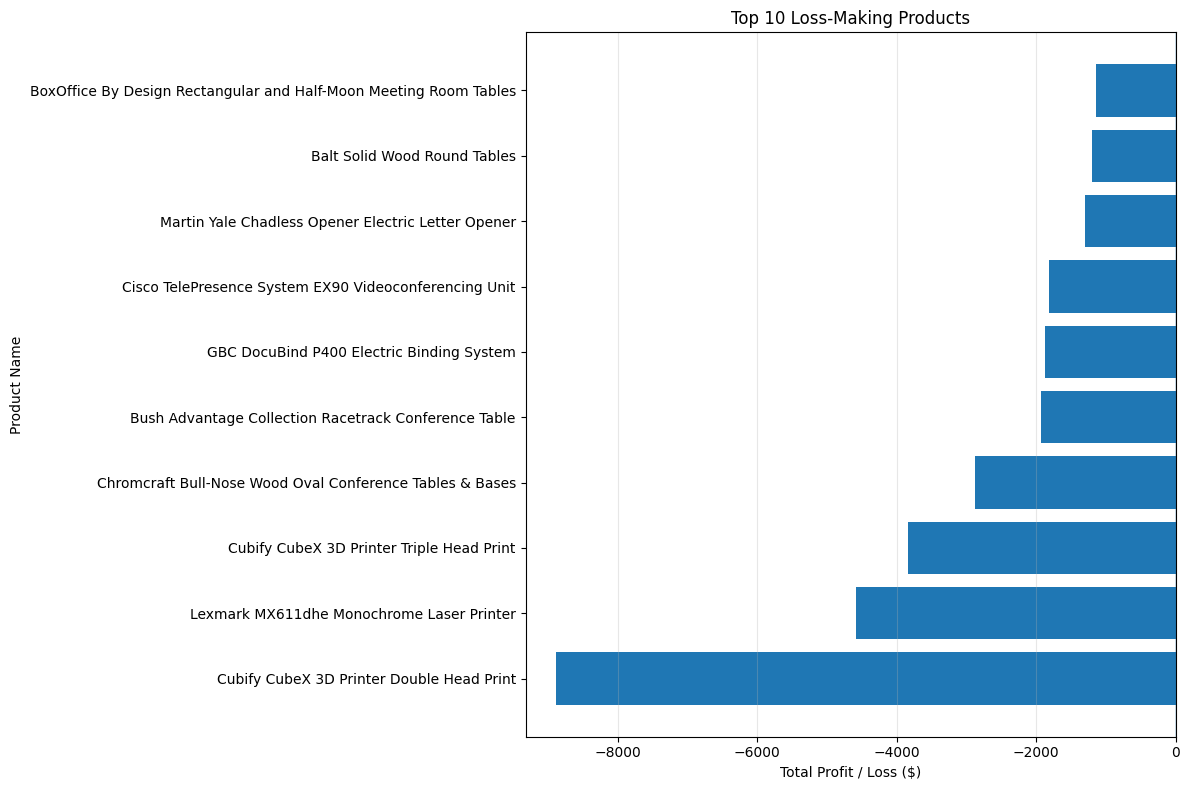

In [39]:
bottom_10_chart = bottom_10_products.sort_values("Total_Profit", ascending=True)

plt.figure(figsize=(12,8))

plt.barh(bottom_10_chart["Product Name"], bottom_10_chart["Total_Profit"])

plt.title("Top 10 Loss-Making Products")
plt.xlabel("Total Profit / Loss ($)")
plt.ylabel("Product Name")
plt.axvline(0, linewidth=1)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## Business Recommendations – Loss-Making Products

1. **Review Product Pricing:** Reassess the selling prices of loss-making products, particularly the Cubify CubeX 3D printers.
2. **Analyze Product Costs:** Investigate purchase costs, shipping expenses, discounts and other costs associated with low-profit products.
3. **Review Discount Strategies:** Evaluate whether excessive discounts are affecting product profitability.
4. **Monitor Product Performance:** Track product-wise sales, profit and quantity regularly.
5. **Evaluate Product Portfolio:** Consider renegotiating supplier costs or reviewing the continuation of consistently loss-making products.

**Important Note:** Negative profit identifies a profitability problem, but the available analysis does not establish its exact cause. Further investigation of product costs, pricing and discounts is required.

# Final Business Insights & Recommendations

## 1. Key Business Insights

### Sales and Profit by Category
- Technology generated the highest sales of USD 836,154.03 and profit of USD 145,454.95.
- Furniture generated substantial sales but had a low profit margin of approximately 2.49%.
- Tables were the biggest loss-making Furniture sub-category, with a loss of USD 17,725.48.

### Regional Performance
- West was the leading region, generating USD 725,457.82 in sales and USD 108,418.45 in profit.
- South recorded the lowest sales and profit among the four regions.
- Central had the lowest profit margin at 7.92%.

### Customer Segment Performance
- Consumer was the largest segment, generating USD 1,161,401.34 in sales and USD 134,119.21 in profit.
- Home Office had the highest profit margin at 14.03%.

### Shipping Performance
- Standard Class generated the highest sales and profit among shipping modes.
- First Class recorded the highest profit margin at 13.93%.

### Product Performance
- Canon imageCLASS 2200 Advanced Copier was the most profitable product, generating USD 25,199.93 in profit.
- Cubify CubeX 3D Printer Double Head Print recorded the largest product-level loss of USD 8,879.97.

### Monthly Performance
- Sales generally increased over the 2014–2017 period.
- Monthly sales and profits fluctuated throughout the period.
- Some months recorded negative profits despite generating sales.

## 2. Business Recommendations

1. **Improve Furniture Profitability:** Review pricing, costs and discount policies for loss-making Furniture products, particularly Tables.
2. **Regional Strategy:** Investigate the reasons behind lower performance in the South and Central regions.
3. **Customer Segment Strategy:** Maintain strong engagement with Consumer customers while exploring opportunities to grow the Home Office segment.
4. **Shipping Strategy:** Review shipping costs and service performance across shipping modes.
5. **Product Portfolio Optimization:** Review consistently loss-making products and evaluate their pricing, costs and sales performance.
6. **Monthly Performance Monitoring:** Track sales, profit and profit margins every month.

## 3. Conclusion

The Sales Data Analysis project helped identify important patterns in sales, profitability, customer segments, regional performance, shipping methods and product performance.

The analysis highlights that high sales do not always translate into high profits. By improving pricing strategies, monitoring discounts, reviewing loss-making products and tracking regional performance, businesses can make better data-driven decisions.

**Tools Used:** Python, Pandas, NumPy, Matplotlib, SQL, Excel and Power BI.

In [40]:
df_clean.to_csv("Superstore_Cleaned.csv", index=False)
print("Cleaned dataset exported successfully")

Cleaned dataset exported successfully
